# Who Gets Studied? Clinical Trial Patterns for Female- and Male-Specific Conditions
## DS 3000 - Project Phase II: Proof of Concept

**Student Names**: Violet Fiorella and Joy Lee

**Date**: November 5th, 2026

## 1. Project Motivation and Questions

### Project Description

Endometriosis affects roughly 10% of women and girls of reproductive age worldwide, about 190 million people, and the World Health Organization reports no known cure (World Health Organization, 2025). Polyendocrine metabolic ovarian syndrome (PMOS), formerly called polycystic ovary syndrome (Merelli, 2026), affects an estimated 10% to 13% of reproductive-age women, a share at or above the endometriosis estimate, and up to 70% of those women are undiagnosed. It also has no cure (World Health Organization, 2026). New treatments for conditions like these reach patients only after clinical trials test them, and the money behind that research is unevenly spread. Arthur Mirin compared National Institutes of Health (NIH) funding with disease burden and found that the NIH devotes a disproportionate share of its resources to diseases that mainly affect men (Mirin, 2021). Two of this project's female-specific conditions appear in Mirin's analysis, and both received less than a quarter of the funding their disease burden would predict (measured in years of healthy life lost), with endometriosis at `$13 million` and uterine fibroids at `$17 million` in 2019 (Mirin, 2021). A National Academies report released in December 2024 (National Academies of Sciences, Engineering, and Medicine, 2025) found that only 8.8% of NIH research spending from 2013 to 2023 went to women's health research, and that share declined over the decade (Society for Women's Health Research, 2024). The committee recommended that Congress appropriate `$15.7 billion` over five years to address the gaps. The NIH responded that the report understated work already underway across its institutes (Society for Women's Health Research, 2024).

The disagreement leaves an open question about what the research itself looks like. Since 1993, NIH-funded trials have been required to include women, and roughly half of participants in NIH-funded trials are now women (Nature, 2023). A 2017 amendment required NIH-funded Phase III trials of FDA-regulated products (large late-stage trials, usually with several hundred or more participants) to report results by sex on ClinicalTrials.gov (National Institutes of Health, 2017), and a 2025 revision of the policy kept that requirement (National Institutes of Health, 2025). That requirement covers NIH-funded trials alone, so industry-sponsored trials fall outside it. Broad inclusion in general trials can coexist with thin research on conditions only women have. Menopause research was hard to measure as of 2023, since the NIH had assigned menopause no funding code of its own (Nature, 2023). NIH spending figures track federal dollars, so they leave out research that drug companies fund themselves. ClinicalTrials.gov, the federal registry of clinical studies, records the size, design, sponsor, and outcome of each trial, including trials paid for by industry.

This project compares trials for four female-specific conditions (endometriosis, polyendocrine metabolic ovarian syndrome, uterine fibroids, and menopause) with trials for four male-specific conditions (benign prostatic hyperplasia, erectile dysfunction, male hypogonadism, and Peyronie's disease). The ClinicalTrials.gov search in this notebook queries PMOS and its older name, polycystic ovary syndrome (PCOS), then merges any trial that appears under the two. Every condition in both groups involves reproductive or hormonal health, and none of them is a cancer, which keeps the comparison balanced.

### Questions of Interest

1. Do trials for female-specific conditions enroll fewer participants, run for different lengths of time, or draw less industry sponsorship than trials for comparable male-specific conditions?
2. Which trial characteristics predict whether a trial finishes as planned or ends early (terminated or withdrawn), and do female-specific trials end early more often?

The first question is inferential, since it asks whether a gap in trial size, length, or funding holds after accounting for differences in trial design. The second is predictive, since it asks which characteristics forecast a trial's outcome before that outcome is known.

### Data Processing Pipeline

1. **Acquisition.** The notebook sends a series of requests for each search term to the `studies` endpoint of the ClinicalTrials.gov API v2, filtering with `query.cond`, requesting 1,000 records per page, and following `nextPageToken` until the API returns no token. Every matching trial is collected.
2. **Ingestion.** Each nested JSON study record is flattened into one row of 16 fields drawn from the identification, status, design, sponsor, eligibility, and location modules.
3. **Merging.** The two PMOS searches merge on NCT ID, the eight condition tables stack into one, trials that matched conditions in both groups are dropped, and trials that matched two conditions in one group keep a single row.
4. **Cleaning.** Rows missing enrollment or start date are dropped, impossible durations are set to missing, phase labels are standardized, and enrollment outliers and sex-eligibility mismatches are flagged.
5. **Feature construction.** The notebook adds log enrollment, actual duration, 0/1 indicators for condition group and industry sponsorship, and the `ended_early` target for the second question.
6. **Output.** The cleaned table is saved as `clinical_trials_clean.csv` for the visualizations and the models.

## 2. Data Acquisition, Cleaning, and Merging

### Data Source

All data comes from the ClinicalTrials.gov API, version 2, which the U.S. National Library of Medicine maintains (U.S. National Library of Medicine, 2025). The API returns JSON and requires no key. Phase I capped each condition at 500 trials, and six of the eight conditions hit that cap, so the trial counts showed the cap and said nothing about the size of each research field. This notebook removes the cap and collects every trial that matches each search term.

| Feature | Type | Description |
|---|---|---|
| `nct_id` | Identifier | ClinicalTrials.gov registry number |
| `title` | Text | Brief trial title |
| `condition_group` | Categorical | Female-specific or male-specific |
| `condition` | Categorical | The condition searched |
| `study_type` | Categorical | Interventional, observational, or expanded access |
| `phase` | Categorical | Trial phase as the API reports it |
| `phase_group` | Categorical | Standardized phase label (built in cleaning) |
| `overall_status` | Categorical | COMPLETED, TERMINATED, WITHDRAWN, RECRUITING, and so on |
| `why_stopped` | Text | Reason given for a trial that stopped early |
| `sponsor_class` | Categorical | Lead sponsor type (INDUSTRY, NIH, OTHER, and so on) |
| `sex_eligibility` | Categorical | Which sexes may enroll (FEMALE, MALE, ALL) |
| `enrollment` | Numeric | Number of participants |
| `enrollment_type` | Categorical | ACTUAL or ESTIMATED enrollment |
| `log_enrollment` | Numeric | Log of enrollment plus one (built in cleaning) |
| `num_locations` | Numeric | Number of trial sites |
| `start_year` | Numeric | Year the trial started |
| `completion_type` | Categorical | ACTUAL or ESTIMATED completion date |
| `duration_months` | Numeric | Months from start date to completion date |
| `duration_actual_months` | Numeric | Duration for trials with an actual completion date |
| `female_specific` | Binary | 1 for female-specific trials, 0 for male-specific trials |
| `industry_sponsor` | Binary | 1 when the lead sponsor is a company |
| `ended_early` | Binary | 1 for terminated or withdrawn, 0 for completed, missing for open trials |
| `enrollment_outlier` | Binary | Flags extremely large studies |
| `sex_mismatch` | Binary | Flags trials enrolling only the sex the condition excludes |

In [1]:
import os
import time
import numpy as np
import pandas as pd
import requests

# Endpoint for version 2 of the ClinicalTrials.gov API
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"

# Each condition label maps to the search terms used to find its trials
CONDITIONS = {
    "Female-specific": {
        "Endometriosis": ["Endometriosis"],
        # PMOS is searched under its new name and its former name, PCOS
        "PMOS": ['"Polyendocrine Metabolic Ovarian Syndrome"', "Polycystic Ovary Syndrome"],
        "Uterine Fibroids": ["Uterine Fibroids"],
        "Menopause": ["Menopause"],
    },
    "Male-specific": {
        "Benign Prostatic Hyperplasia": ["Benign Prostatic Hyperplasia"],
        "Erectile Dysfunction": ["Erectile Dysfunction"],
        "Male Hypogonadism": ["Male Hypogonadism"],
        "Peyronie Disease": ["Peyronie Disease"],
    },
}

# The API allows up to 1,000 records per page, which keeps the request count low
PAGE_SIZE = 1000

# None collects every matching trial, and a number caps each search at that many trials
MAX_PER_CONDITION = None

In [2]:
def fetch_studies(term, max_studies=MAX_PER_CONDITION, page_size=PAGE_SIZE):
    """Return the raw study records for one condition search term.

    The function follows the API's page tokens until the results run out,
    or until max_studies records have been collected when a cap is set.
    """
    studies = []
    params = {"query.cond": term, "pageSize": page_size, "format": "json"}
    while True:
        response = requests.get(BASE_URL, params=params, timeout=60)
        # Raise a clear error if the API returns a failed status code
        response.raise_for_status()
        data = response.json()
        studies.extend(data.get("studies", []))

        # Stop once the optional cap is reached
        if max_studies is not None and len(studies) >= max_studies:
            return studies[:max_studies]

        # A missing token means this was the last page of results
        token = data.get("nextPageToken")
        if token is None:
            return studies
        params["pageToken"] = token

        # Short pause to stay polite to the public API
        time.sleep(0.3)


def parse_date(date_string):
    """Convert 'YYYY-MM' or 'YYYY-MM-DD' strings to Timestamps, and empty values to NaT."""
    if not date_string:
        return pd.NaT
    # Month-only dates are pinned to the first day of the month
    if len(date_string) == 7:
        date_string += "-01"
    return pd.to_datetime(date_string, errors="coerce")


def flatten_study(study, group, condition):
    """Pull the 16 fields used in this project out of one nested study record."""
    protocol = study.get("protocolSection", {})
    ident = protocol.get("identificationModule", {})
    status = protocol.get("statusModule", {})
    design = protocol.get("designModule", {})
    sponsor = protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {})
    eligibility = protocol.get("eligibilityModule", {})
    locations = protocol.get("contactsLocationsModule", {}).get("locations", [])
    enrollment_info = design.get("enrollmentInfo", {})
    completion = status.get("completionDateStruct", {})
    phases = design.get("phases", [])

    return {
        "nct_id": ident.get("nctId"),
        "title": ident.get("briefTitle"),
        "condition_group": group,
        "condition": condition,
        "study_type": design.get("studyType"),
        # Combined phases such as PHASE1 and PHASE2 are joined into one string
        "phase": "|".join(phases) if phases else None,
        "overall_status": status.get("overallStatus"),
        "why_stopped": status.get("whyStopped"),
        "sponsor_class": sponsor.get("class"),
        "sex_eligibility": eligibility.get("sex"),
        "enrollment": enrollment_info.get("count"),
        "enrollment_type": enrollment_info.get("type"),
        "num_locations": len(locations),
        "start_date": parse_date(status.get("startDateStruct", {}).get("date")),
        "completion_date": parse_date(completion.get("date")),
        "completion_type": completion.get("type"),
    }

In [3]:
# Collect trials for every condition, merging the PMOS results across its two search terms
rows = []
for group, condition_map in CONDITIONS.items():
    for label, terms in condition_map.items():
        seen_ids = set()
        for term in terms:
            studies = fetch_studies(term)
            new_count = 0
            for s in studies:
                nct_id = s.get("protocolSection", {}).get("identificationModule", {}).get("nctId")
                # Skip trials already collected under the other PMOS search term
                if nct_id in seen_ids:
                    continue
                seen_ids.add(nct_id)
                rows.append(flatten_study(s, group, label))
                new_count += 1
            print(f"{group:16} {label:30} {term:45} {new_count} new trials")
        print(f"{group:16} {label:30} {len(seen_ids)} trials total\n")

trials_raw = pd.DataFrame(rows)
print(trials_raw.shape)

Female-specific  Endometriosis                  Endometriosis                                 959 new trials
Female-specific  Endometriosis                  959 trials total

Female-specific  PMOS                           "Polyendocrine Metabolic Ovarian Syndrome"    12 new trials
Female-specific  PMOS                           Polycystic Ovary Syndrome                     1064 new trials
Female-specific  PMOS                           1076 trials total

Female-specific  Uterine Fibroids               Uterine Fibroids                              502 new trials
Female-specific  Uterine Fibroids               502 trials total

Female-specific  Menopause                      Menopause                                     1923 new trials
Female-specific  Menopause                      1923 trials total

Male-specific    Benign Prostatic Hyperplasia   Benign Prostatic Hyperplasia                  878 new trials
Male-specific    Benign Prostatic Hyperplasia   878 trials total

Male-specific

### Merging the Condition Searches

The eight conditions come from nine searches, since PMOS is searched under its current and former names, and the collection loop above merges the two PMOS searches on NCT ID as it runs. The cell below works on the stacked table of all eight conditions and removes two kinds of overlap. A trial that matched a female-specific condition and a male-specific condition belongs to neither group cleanly, so it is dropped. A trial that matched two conditions within the same group keeps its first row, which leaves one row per trial.

In [4]:
# Find trials that appear under conditions from both groups and drop them
groups_per_trial = trials_raw.groupby("nct_id")["condition_group"].nunique()
mixed_ids = groups_per_trial[groups_per_trial > 1].index
trials = trials_raw[~trials_raw["nct_id"].isin(mixed_ids)]

# Keep one row per trial when a trial matched two conditions in the same group
rows_before = len(trials)
trials = trials.drop_duplicates(subset="nct_id", keep="first").reset_index(drop=True)

print(f"Removed {len(mixed_ids)} cross-group trials")
print(f"Removed {rows_before - len(trials)} same-group duplicate rows")
print(f"{len(trials)} unique trials remain")
print(trials["condition"].value_counts())

Removed 8 cross-group trials
Removed 117 same-group duplicate rows
6276 unique trials remain
condition
Menopause                       1896
PMOS                            1066
Endometriosis                    959
Benign Prostatic Hyperplasia     875
Erectile Dysfunction             723
Uterine Fibroids                 463
Male Hypogonadism                253
Peyronie Disease                  41
Name: count, dtype: int64


### Missing Values

Enrollment and start date feed both questions, and a trial missing either one fits in neither model, so those rows are dropped. Completion date stays missing for some ongoing trials, and the duration step below handles those rows.

In [5]:
# Count missing values in each column before cleaning
print(trials.isna().sum())

# Drop rows missing a field that both questions depend on
rows_before = len(trials)
trials = trials.dropna(subset=["enrollment", "start_date"]).reset_index(drop=True)
print(f"\nDropped {rows_before - len(trials)} rows missing enrollment or start date, {len(trials)} remain")

nct_id                0
title                 0
condition_group       0
condition             0
study_type            0
phase              1473
overall_status        0
why_stopped        5833
sponsor_class         0
sex_eligibility       3
enrollment           53
enrollment_type     206
num_locations         0
start_date           32
completion_date     158
completion_type     267
dtype: int64

Dropped 73 rows missing enrollment or start date, 6203 remain


### Trial Duration

Duration is measured in months from the start date to the completion date. Durations below zero or above 40 years are set to missing. The six durations above that cutoff all belong to long-running cohorts and registries, such as the Nurses' Health Study, and the longest lists a completion date in 2100. Studies on that timescale measure something different from a typical trial, so they would distort any duration comparison between groups. Ongoing trials list an estimated completion date, so their durations describe a plan. `duration_actual_months` keeps durations only for trials whose completion date is marked ACTUAL, and the first question will compare that column between groups.

In [6]:
# Derive the time-based numeric features
trials["start_year"] = trials["start_date"].dt.year.astype(int)
trials["duration_months"] = ((trials["completion_date"] - trials["start_date"]).dt.days / 30.44).round(1)

# Set impossible durations to missing (below zero or above 40 years)
MAX_DURATION_MONTHS = 40 * 12
bad_duration = (trials["duration_months"] < 0) | (trials["duration_months"] > MAX_DURATION_MONTHS)
print(f"{bad_duration.sum()} durations set to missing")
display(trials.loc[bad_duration, ["nct_id", "title", "start_date", "completion_date", "duration_months"]])
trials.loc[bad_duration, "duration_months"] = np.nan

# Keep a separate duration column for trials that have actually finished
trials["duration_actual_months"] = trials["duration_months"].where(trials["completion_type"] == "ACTUAL")
print(trials["completion_type"].value_counts(dropna=False))

6 durations set to missing


,nct_id,title,start_date,completion_date,duration_months
940,NCT03285230,The French E3N Prospective Cohort Study,1990-06-15,2046-12-31,678.5
1616,NCT03991507,PCOS (Polycystic Ovarian Syndrome) Patients,2010-01-01,2050-12-31,491.9
2043,NCT00005095,Specimen and Data Study for Ovarian Cancer Ear...,2000-03-01,2040-12-01,489.0
3123,NCT06487130,Virtual perI-/Menopause Registry of AusTrALia,2023-08-03,2073-08-01,599.9
3499,NCT00005152,Nurses' Health Study (Cardiovascular Component),1980-08-01,2029-06-01,585.9
6095,NCT01793168,Rare Disease Patient Registry & Natural Histor...,2010-07-01,2100-12-01,1084.9


completion_type
ACTUAL       3618
ESTIMATED    2365
None          220
Name: count, dtype: int64


### Trial Phase

The API leaves the phase field empty for observational studies and uses NA for interventional studies with no phase, such as many device and behavioral trials. Phase I kept both, which put two different kinds of study under similar labels. `phase_group` gives each study one readable label, groups early Phase 1 with Phase 1, and keeps combined phases such as Phase 1/2 as their own categories. The raw `phase` column renames NA to NO_PHASE, since pandas reads the text NA as a missing value when the saved CSV is loaded again.

In [7]:
# Map the API's phase codes to readable labels
PHASE_LABELS = {
    "EARLY_PHASE1": "Phase 1",
    "PHASE1": "Phase 1",
    "PHASE1|PHASE2": "Phase 1/2",
    "PHASE2": "Phase 2",
    "PHASE2|PHASE3": "Phase 2/3",
    "PHASE3": "Phase 3",
    "PHASE4": "Phase 4",
    "NA": "No phase",
}
trials["phase_group"] = trials["phase"].map(PHASE_LABELS)

# Observational studies have no phase, so they get their own label
trials.loc[trials["study_type"] == "OBSERVATIONAL", "phase_group"] = "Observational"

# Anything left unlabeled, such as expanded access programs, goes into one group
trials["phase_group"] = trials["phase_group"].fillna("Other")

# Rename the API's NA code so pandas keeps it as text when the saved CSV is read back
trials["phase"] = trials["phase"].replace("NA", "NO_PHASE")

pd.crosstab(trials["phase_group"], trials["condition_group"])

condition_group,Female-specific,Male-specific
phase_group,,
No phase,1702,625
Observational,1062,393
Phase 1,269,157
Phase 1/2,56,34
Phase 2,368,173
Phase 2/3,62,24
Phase 3,393,222
Phase 4,411,252


### Enrollment

Enrollment is heavily right-skewed. Phase I found a mean near 2,000 against a median near 78, driven by a registry study listing 1.6 million participants. Large registries are real studies, so they stay in the data, and `enrollment_outlier` flags any trial whose log enrollment sits more than three interquartile ranges above the third quartile. That cutoff falls at about 15,600 participants and flags 27 trials, and the five largest are all observational studies. `log_enrollment` (the log of enrollment plus one) compresses the scale for plots and regression, and adding one keeps trials with zero participants defined. Zero enrollment appears only among withdrawn trials, which stopped before enrolling anyone, and 168 of the 170 withdrawn trials report zero.

In [8]:
# Compress the long right tail of enrollment
trials["log_enrollment"] = np.log1p(trials["enrollment"])

# Flag extreme studies using the interquartile range on the log scale
q1, q3 = trials["log_enrollment"].quantile([0.25, 0.75])
upper_fence = q3 + 3 * (q3 - q1)
trials["enrollment_outlier"] = (trials["log_enrollment"] > upper_fence).astype(int)
print(f"Outlier cutoff is {np.expm1(upper_fence):,.0f} participants, {trials['enrollment_outlier'].sum()} trials flagged")
display(trials.nlargest(5, "enrollment")[["nct_id", "title", "study_type", "enrollment"]])

# Check which statuses report zero participants
pd.crosstab(trials["enrollment"] == 0, trials["overall_status"])

Outlier cutoff is 15,572 participants, 27 trials flagged


,nct_id,title,study_type,enrollment
788,NCT01267851,Clinical Database and Biobank of Patients With...,OBSERVATIONAL,1600000.0
2807,NCT06999317,CARAMEL: Retrospective Study for Personalized ...,OBSERVATIONAL,1500000.0
3303,NCT06033521,A Study to Learn More About the Menopausal Hor...,OBSERVATIONAL,1036294.0
198,NCT06217315,Endometriosis and Health Care System Utilizati...,OBSERVATIONAL,1000000.0
1335,NCT04196595,Apple Women's Health Study,OBSERVATIONAL,500000.0


overall_status,ACTIVE_NOT_RECRUITING,COMPLETED,ENROLLING_BY_INVITATION,NOT_YET_RECRUITING,RECRUITING,SUSPENDED,TERMINATED,UNKNOWN,WITHDRAWN
enrollment,,,,,,,,,
False,181,3379,49,379,661,15,321,1048,2
True,0,0,0,0,0,0,0,0,168


### Sex Eligibility Check

Some trials enroll only the sex their condition group excludes, and their titles show four causes. Every male hypogonadism trial of this kind enrolls only female participants and describes a condition in women, such as estrogen dosing in Turner syndrome or prenatal testing in pregnancy, so the search term also matched hypogonadism in women. Three more trials match their condition search by accident, a menopause trial on sperm DNA fragmentation and two erectile dysfunction trials on ovarian reserve and breast cancer rehabilitation. The cell below drops these 12 trials. The same searches may have matched trials open to both sexes on unrelated conditions, which a later title review can check.

Eight female-specific trials are early-phase drug studies that enroll only male participants, most of them in healthy volunteers, with seven for endometriosis and one for PMOS. These trials fit a pattern with a long history, a pattern that is part of why I set out on this project. A 1977 FDA guidance document instructed investigators to exclude any woman capable of becoming pregnant from Phase I trials, even women using birth control, and ultimately excluded women from drug trials altogether (Meek, 2019). The FDA lifted that restriction in July 1993 and began encouraging women to enter early-phase trials (U.S. Food and Drug Administration, 2025), yet these endometriosis trials were registered more than two decades later. For these seven drugs, the first data on how each drug behaves in the body comes from people who will never have the condition it targets. Three erectile dysfunction trials enroll only female participants and study erectile prostheses or aids after phalloplasty. Two more trials, a menopause hot-flash study and an erectile dysfunction drug trial, appear to carry a sex field entered in error. These 13 trials belong to their condition's research, so they stay in the data with `sex_mismatch` flagging them.

In [9]:
# Male hypogonadism trials that enroll only female participants study conditions in women, so they are dropped
women_only_hypogonadism = (trials["condition"] == "Male Hypogonadism") & (trials["sex_eligibility"] == "FEMALE")
print(f"Dropped {women_only_hypogonadism.sum()} male hypogonadism trials that enroll only female participants")
trials = trials[~women_only_hypogonadism].reset_index(drop=True)

# These trials matched a condition search by accident, based on a review of their titles
# (sperm DNA under menopause, ovarian reserve and breast cancer rehabilitation under erectile dysfunction)
OFF_TOPIC_IDS = ["NCT07873502", "NCT05743218", "NCT04166279"]
print(f"Dropped {trials['nct_id'].isin(OFF_TOPIC_IDS).sum()} off-topic trials")
trials = trials[~trials["nct_id"].isin(OFF_TOPIC_IDS)].reset_index(drop=True)

# Flag trials that enroll only the sex the condition excludes
female_only_men = (trials["condition_group"] == "Female-specific") & (trials["sex_eligibility"] == "MALE")
male_only_women = (trials["condition_group"] == "Male-specific") & (trials["sex_eligibility"] == "FEMALE")
trials["sex_mismatch"] = (female_only_men | male_only_women).astype(int)

print(f"{trials['sex_mismatch'].sum()} trials flagged")

# Show full titles so each flagged trial can be reviewed
with pd.option_context("display.max_colwidth", None):
    display(trials.loc[trials["sex_mismatch"] == 1, ["nct_id", "condition", "sex_eligibility", "title"]])

Dropped 9 male hypogonadism trials that enroll only female participants
Dropped 3 off-topic trials
13 trials flagged


,nct_id,condition,sex_eligibility,title
201,NCT06949124,Endometriosis,MALE,"A Phase 1 Clinical Study to Evaluate the Effects of SHR7280 on the Pharmacokinetics of Midazolam, S-warfarin, Omeprazole, Digoxin, and Rosuvastatin in Healthy Subjects"
304,NCT04027192,Endometriosis,MALE,"Study to Test the Safety of Increasing Multiple Doses of BAY2328065 Given by Mouth, How the Drug is Tolerated and Acts in the Human Body of Healthy Male Participants. Alteration of the Study Drug Effects by Another Drug and the Availability of the Drug Given in Different Formulations is Also Tested."
317,NCT04265781,Endometriosis,MALE,Study on the Safety of Drug BAY1817080 at Different Doses and the Way the Body Absorbs and Eliminates the Drug in Japanese Healthy Adult Male Participants
497,NCT05517746,Endometriosis,MALE,"Study on the Safety of the Drug BAY2395840 at Different Doses, the Way the Body Absorbs, Distributes and Excretes the Drug Including the Effect of Its Formulation (Tablet or Liquid) and the Effect of Food on the Absorption, Distribution or Excretion of the Drug in Healthy Male Participants"
648,NCT03427788,Endometriosis,MALE,"BAY2328065 Single Dose Escalation, Safety and Tolerability, Pharmacokinetics, Relative Bioavailability, Food Effect"
722,NCT04487431,Endometriosis,MALE,A Trial to Learn How a New Liquid Form of BAY1817080 is Tolerated and Taken up by the Body of Healthy Male Participants (Part A). By Labeling BAY1817080 With a Radioactive Substance (Carbon 14) Researchers Want to Learn How the Study Drug is Processed and Excreted by the Body After Dosing (Part B)
730,NCT03773068,Endometriosis,MALE,"A Study in Healthy Volunteers Investigating How Quickly and to What Extent BAY1817080 is Taken up, Distributed, Broken Down and Eliminated From the Body, as Well as the Difference Between 2 Different Types of Tablets of BAY1817080 and the Difference Between Oral Dose and Dose in the Vein"
1082,NCT03255889,PMOS,MALE,Absorption and Tolerability Studies of an Emulsion Containing the Coconut Oil-derived Glycerol Tridecanoate in Healthy Men
3243,NCT07402096,Menopause,MALE,Effect of a Mindfulness-Based Stress Reduction Program on Hot Flashes and Sleep Quality in Menopausal Women: A Randomized Controlled Trial
5429,NCT01364701,Erectile Dysfunction,FEMALE,Evaluation of Safety and Effectiveness of 2 Lower Dose Combined PDE5i's Versus Single Maximal Dose PDE5i Treatment


In [10]:
# Show when each male-only endometriosis trial started, to date them against the FDA's 1993 change
endo_male_only = trials[(trials["condition"] == "Endometriosis") & (trials["sex_mismatch"] == 1)]
display(endo_male_only[["nct_id", "start_year"]].sort_values("start_year"))

,nct_id,start_year
648,NCT03427788,2018
730,NCT03773068,2018
304,NCT04027192,2019
497,NCT05517746,2019
317,NCT04265781,2020
722,NCT04487431,2020
201,NCT06949124,2025


### Features for Modeling

`female_specific` and `industry_sponsor` recode condition group and sponsor class as 0/1 columns. `ended_early` is the target for the second question. It equals 1 for terminated or withdrawn trials and 0 for completed trials. Trials still recruiting, active, suspended, or of unknown status have no final outcome, so they get a missing value and the second model will leave them out.

In [11]:
# Recode the group and sponsor columns as 0/1 indicators
trials["female_specific"] = (trials["condition_group"] == "Female-specific").astype(int)
trials["industry_sponsor"] = (trials["sponsor_class"] == "INDUSTRY").astype(int)

# Build the target for the second question, leaving open trials missing
trials["ended_early"] = np.select(
    [trials["overall_status"].isin(["TERMINATED", "WITHDRAWN"]), trials["overall_status"] == "COMPLETED"],
    [1, 0],
    default=np.nan,
)

# Show how many closed trials ended early in each group
closed_counts = trials.dropna(subset=["ended_early"]).groupby("condition_group")["ended_early"].agg(["count", "sum", "mean"])
closed_counts.columns = ["closed_trials", "ended_early", "share_ended_early"]
closed_counts.round(3)

,closed_trials,ended_early,share_ended_early
condition_group,,,
Female-specific,2686,347.0,0.129
Male-specific,1179,144.0,0.122


In [12]:
# Put the final columns in a readable order
CLEAN_COLUMNS = [
    "nct_id", "title", "condition_group", "condition", "female_specific",
    "study_type", "phase", "phase_group", "overall_status", "why_stopped", "ended_early",
    "sponsor_class", "industry_sponsor", "sex_eligibility", "sex_mismatch",
    "enrollment", "enrollment_type", "log_enrollment", "enrollment_outlier",
    "num_locations", "start_date", "start_year", "completion_date", "completion_type",
    "duration_months", "duration_actual_months",
]
trials_clean = trials[CLEAN_COLUMNS].reset_index(drop=True)
trials_clean.info()

# Save the cleaned table
OUTPUT_PATH = "clinical_trials_clean.csv"
trials_clean.to_csv(OUTPUT_PATH, index=False)
print(f"\nSaved to {OUTPUT_PATH} in the notebook's folder")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6191 entries, 0 to 6190
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   nct_id                  6191 non-null   object        
 1   title                   6191 non-null   object        
 2   condition_group         6191 non-null   object        
 3   condition               6191 non-null   object        
 4   female_specific         6191 non-null   int64         
 5   study_type              6191 non-null   object        
 6   phase                   4739 non-null   object        
 7   phase_group             6191 non-null   object        
 8   overall_status          6191 non-null   object        
 9   why_stopped             441 non-null    object        
 10  ended_early             3865 non-null   float64       
 11  sponsor_class           6191 non-null   object        
 12  industry_sponsor        6191 non-null   int64   

## 3. Visualizations

### First Visualization: Median Participant Enrollment by Condition Group

This visualization compares the median number of participants enrolled in female-specific and male-specific clinical trials. Only trials with actual enrollment data are included.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

#Loading the cleaned clinical trial data
df = pd.read_csv("clinical_trials_clean.csv")
df.head()

,nct_id,title,condition_group,condition,female_specific,study_type,phase,phase_group,overall_status,why_stopped,...,enrollment_type,log_enrollment,enrollment_outlier,num_locations,start_date,start_year,completion_date,completion_type,duration_months,duration_actual_months
0,NCT04107129,Predicting Endometrial Receptivity for Optimal...,Female-specific,Endometriosis,1,OBSERVATIONAL,NaN,Observational,COMPLETED,NaN,...,ACTUAL,4.343805,0,1,2020-07-01,2020,2024-07-30,ACTUAL,48.9,48.9
1,NCT06414083,Histologic Comparison of Ablative Techniques f...,Female-specific,Endometriosis,1,INTERVENTIONAL,NO_PHASE,No phase,RECRUITING,NaN,...,ESTIMATED,4.955827,0,1,2024-05-09,2024,2025-06-09,ESTIMATED,13.0,NaN
2,NCT05560646,A Study to Investigate Efficacy and Safety of ...,Female-specific,Endometriosis,1,INTERVENTIONAL,PHASE2,Phase 2,COMPLETED,NaN,...,ACTUAL,5.872118,0,86,2022-10-25,2022,2025-05-28,ACTUAL,31.1,31.1
3,NCT01056042,Efficacy of Injectable Contraceptive and Oral ...,Female-specific,Endometriosis,1,INTERVENTIONAL,PHASE4,Phase 4,COMPLETED,NaN,...,ESTIMATED,4.727388,0,1,2007-06-01,2007,2011-10-01,ACTUAL,52.0,52.0
4,NCT02427386,Homeopathic Treatment of Chronic Pelvic Pain i...,Female-specific,Endometriosis,1,INTERVENTIONAL,PHASE4,Phase 4,COMPLETED,NaN,...,ACTUAL,3.931826,0,0,2014-05-01,2014,2016-12-01,ACTUAL,31.0,31.0


In [2]:
#Retrieving column names in data
df.columns.tolist()

['nct_id',
 'title',
 'condition_group',
 'condition',
 'female_specific',
 'study_type',
 'phase',
 'phase_group',
 'overall_status',
 'why_stopped',
 'ended_early',
 'sponsor_class',
 'industry_sponsor',
 'sex_eligibility',
 'sex_mismatch',
 'enrollment',
 'enrollment_type',
 'log_enrollment',
 'enrollment_outlier',
 'num_locations',
 'start_date',
 'start_year',
 'completion_date',
 'completion_type',
 'duration_months',
 'duration_actual_months']

In [3]:
#Checking the types of enrollment in data
df["enrollment_type"].value_counts(dropna=False)

enrollment_type
ACTUAL       3771
ESTIMATED    2276
NaN           144
Name: count, dtype: int64

In [4]:
#Distinguish the trials with actual enrollments
actual_trials = df[df['enrollment_type'] == "ACTUAL"]

#Comparing the median enrollment between condition groups
median_enrollment = actual_trials.groupby("condition_group")["enrollment"].median()
median_enrollment

condition_group
Female-specific    65.0
Male-specific      80.0
Name: enrollment, dtype: float64

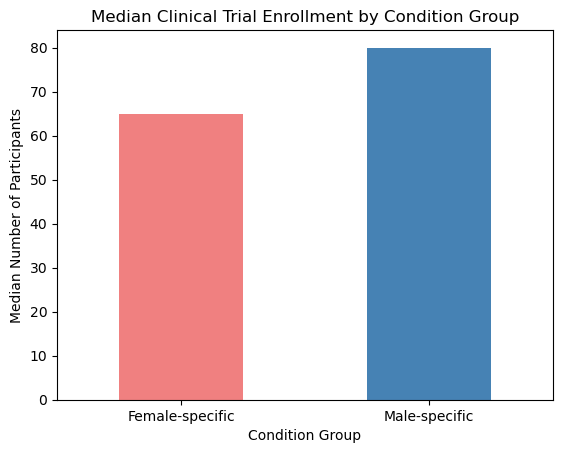

In [5]:
#Bar Chart
median_enrollment.plot(kind="bar", color=["lightcoral", "steelblue"])

plt.title("Median Clinical Trial Enrollment by Condition Group")
plt.xlabel("Condition Group")
plt.ylabel("Median Number of Participants")
plt.xticks(rotation=0)
plt.show()

### Interpretation

Among clinical trials reporting actual enrollment, male-specific trials had a median enrollment of 80 participants, compared to 65 participants for female-specific trials. This is a difference of 15 participants, suggesting that male-specific trials in this dataset tend to have slightly higher enrollment. However, this comparison alone does not explain why the difference exists.

### Second Visualization: Clinical Trial Status by Condition Group

This visualization will compare the percentages of withdrawn, completed, and terminated clinical trials between female-specific and male-specific conditions.

In [6]:
#Checking the different clinical trial statuses
df["overall_status"].value_counts(dropna = False)

overall_status
COMPLETED                  3374
UNKNOWN                    1043
RECRUITING                  659
NOT_YET_RECRUITING          379
TERMINATED                  321
ACTIVE_NOT_RECRUITING       181
WITHDRAWN                   170
ENROLLING_BY_INVITATION      49
SUSPENDED                    15
Name: count, dtype: int64

In [7]:
#Finding the trials that were either completed, terminated, or withdrawn
finished_trials = df[df["overall_status"].isin(
    ["COMPLETED", "TERMINATED", "WITHDRAWN"]
)]

#Counting female/male specific status
status_counts = pd.crosstab(
    finished_trials["condition_group"],
    finished_trials["overall_status"]
)

#Conversion of counts into a percentage value
status_percentages = status_counts.div(
    status_counts.sum(axis = 1), axis = 0
) * 100

status_percentages

overall_status,COMPLETED,TERMINATED,WITHDRAWN
condition_group,,,
Female-specific,87.081162,8.786299,4.132539
Male-specific,87.786260,7.209500,5.004241


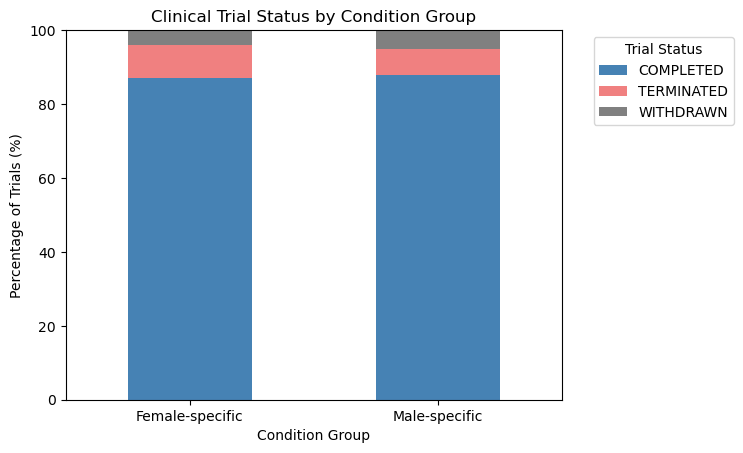

In [8]:
#Stacked Bar Chart
status_percentages.plot(
    kind="bar",
    stacked=True,
    color=["steelblue", "lightcoral", "gray"]
)

plt.title("Clinical Trial Status by Condition Group")
plt.xlabel("Condition Group")
plt.ylabel("Percentage of Trials (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Trial Status", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

### Interpretation

Both condition groups had a similar completion percentage under the completed, terminated, and withdrawn classified trials. Around 87.08% and 87.79% of the female and male specific trials were completed, correspondingly. The male specific trials had a higher withdrawal percentage of 5.00% compared to the female specific trials of 4.13%. The female-specific trials had a higher termination percentage of 8.79% compared to the male-specific trial of 7.21%. In general, these differences were not drastic and relatively similar. Additionally, completion of a trial does not mean the success of a trial. These percentage values only include trials with one of the three selected statuses.

## 4. Functions for Verifying a Machine Learning Model

### Function 1. Classification Metrics by Group

When most closed trials finish as planned, a classifier for the second question can score high accuracy by predicting completion for every trial, and that model would catch zero trials that end early. This function reports precision and recall for the ended-early class beside overall accuracy, and it lists the accuracy of that always-complete baseline so any real model has a clear number to beat. Recall measures the share of trials that actually ended early which the model catches, and precision measures the share of the model's ended-early predictions that turn out correct. Passing `condition_group` as `groups` repeats every metric for female-specific and male-specific trials separately. A model that scores well overall could still miss far more early endings in one group, and for this project that gap would repeat the disparity the questions set out to measure.

In [13]:
def evaluate_classifier(y_true, y_pred, groups=None, positive_label=1):
    """Score binary predictions against true labels, overall and within each group.

    y_true holds the true labels and y_pred holds the model's predicted labels.
    groups is an optional array of group labels, such as condition_group, that
    splits the scores by group. positive_label is the class treated as positive,
    which is 1 (ended early) for the second question.

    Returns a DataFrame with one row for all trials plus one row per group. Each
    row holds the confusion matrix counts, accuracy, precision, recall, F1 score,
    and the accuracy of always predicting the most common class.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must have the same length")

    def score(t, p):
        # Confusion matrix counts for the positive class
        tp = int(np.sum((t == positive_label) & (p == positive_label)))
        fp = int(np.sum((t != positive_label) & (p == positive_label)))
        fn = int(np.sum((t == positive_label) & (p != positive_label)))
        tn = int(np.sum((t != positive_label) & (p != positive_label)))
        n = len(t)

        # Each ratio is left missing when its denominator is zero
        accuracy = (tp + tn) / n if n else np.nan
        precision = tp / (tp + fp) if (tp + fp) else np.nan
        recall = tp / (tp + fn) if (tp + fn) else np.nan
        if np.isnan(precision) or np.isnan(recall) or (precision + recall) == 0:
            f1 = np.nan
        else:
            f1 = 2 * precision * recall / (precision + recall)

        # Accuracy of always guessing whichever class is more common
        positive_rate = np.mean(t == positive_label) if n else np.nan
        baseline_accuracy = max(positive_rate, 1 - positive_rate) if n else np.nan

        return {
            "n": n, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1,
            "baseline_accuracy": baseline_accuracy,
        }

    results = {"All trials": score(y_true, y_pred)}
    if groups is not None:
        groups = np.asarray(groups)
        # Repeat the scoring inside each group
        for g in sorted(pd.unique(groups)):
            mask = groups == g
            results[g] = score(y_true[mask], y_pred[mask])

    return pd.DataFrame(results).T.round(3)

In [14]:
# Small hand-checked example. Group A gets 2 of its 3 positives right and group B gets 0 of 1
example_true = [1, 1, 1, 0, 0, 1, 0, 0]
example_pred = [1, 1, 0, 0, 1, 0, 0, 0]
example_groups = ["A", "A", "A", "A", "B", "B", "B", "B"]
evaluate_classifier(example_true, example_pred, groups=example_groups)

,n,TP,FP,FN,TN,accuracy,precision,recall,f1,baseline_accuracy
All trials,8.0,2.0,1.0,2.0,3.0,0.625,0.667,0.500,0.571,0.50
A,4.0,2.0,0.0,1.0,1.0,0.750,1.000,0.667,0.800,0.75
B,4.0,0.0,1.0,1.0,2.0,0.500,0.000,0.000,NaN,0.75


In [ ]:
# Baseline check on the real data, predicting that every closed trial completed
closed = trials_clean.dropna(subset=["ended_early"])
baseline_predictions = np.zeros(len(closed), dtype=int)
evaluate_classifier(closed["ended_early"].astype(int), baseline_predictions, groups=closed["condition_group"])

With every prediction set to completed, recall for the ended-early class is zero, precision is undefined, and accuracy equals the share of closed trials that completed. That accuracy is the floor a model for the second question needs to clear, and the group rows show the floor for female-specific and male-specific trials separately. In this data the floor sits near 87% for both groups, so a model could report 87% accuracy while identifying none of the roughly 490 trials that ended early. Female-specific and male-specific trials also end early at nearly the same rate, about 13% and 12%, so the second question turns on whether that similarity holds once sponsor, phase, and enrollment are accounted for.


### Function 2. Mean Absolute Error (MAE)

This function will find the Mean Absolute Error (MAE) of a machine learning model. MAE measures the average difference between predicted and actual numerical values. For this project, it could be used to evaluate how accurately a regression model predicts clinical trial enrollment. A lower MAE indicates that the model's predictions are closer to the actual enrollment values.

In [12]:
# Function to calculate Mean Absolute Error
def calculate_mae(actual, predicted):
    errors = []
    # Finding the absolute differences
    for i in range(len(actual)):
        error = abs(actual[i] - predicted[i])
        errors.append(error)
    # Finding the average error
    mae = sum(errors) / len(errors)
    
    return mae

In [13]:
#Testing the function with an example value set
actual = [100, 200, 150, 300]
predicted = [110, 180, 160, 290]

print(calculate_mae(actual, predicted))

12.5


## 5. Ethical Implications

When using clinical trial data to compare female specific and male specific conditions, there are several ethical considerations that are involved. Unequal representation in clinical trial data sets is one of the main concerns. Specific conditions may have more studies done than others, which could ultimately impact the results and potentially create bias in an analysis. On top of this, the total number of participants enrolled in a clinical trial doesn't necessarily represent the amount of attention or funding that was invested into a condition. Other factors that influence enrollment are prevalence of a condition, eligibility requirements, and study design.

Additionally, another concern is the machine learning interpretation level in these differences. A model that is trained on data that consists of inequalities within the research participation could reinforce the same patterns rather than providing an unbiased prediction. It is crucial to realize that classifying conditions as female specific or male specific doesn't fully represent everyone affected by these conditions. This includes transgender and non-binary individuals. Keeping the above information in mind, any conclusions made from this project should be interpreted carefully and should not be used alone to make decisions about research, funding, or healthcare priorities.

## References

Meek, C. (2019, October 31). "General considerations for the clinical evaluation of drugs" (1977), by the United States Food and Drug Administration. *Embryo Project Encyclopedia*. https://hdl.handle.net/10776/13131

Merelli, A. (2026, May 12). *PCOS's new name is PMOS, a small letter change that required a big scientific process*. STAT. https://www.statnews.com/2026/05/12/pcos-now-called-pmos-polyendocrine-metabolic-ovarian-syndrome/

Mirin, A. A. (2021). Gender disparity in the funding of diseases by the U.S. National Institutes of Health. *Journal of Women's Health, 30*(7), 956-963. https://doi.org/10.1089/jwh.2020.8682

National Academies of Sciences, Engineering, and Medicine. (2025). *A new vision for women's health research: Transformative change at the National Institutes of Health*. The National Academies Press. https://doi.org/10.17226/28586

National Institutes of Health. (2017, November 28). *Amendment: NIH policy and guidelines on the inclusion of women and minorities as subjects in clinical research* (Notice No. NOT-OD-18-014). https://grants.nih.gov/grants/guide/notice-files/NOT-OD-18-014.html

National Institutes of Health. (2025, July 17). *Revision: NIH policy and guidelines on the inclusion of women and minorities as subjects in clinical research* (Notice No. NOT-OD-25-131). https://grants.nih.gov/grants/guide/notice-files/NOT-OD-25-131.html

Nature. (2023, May 3). Women's health: End the disparity in funding [Editorial]. *Nature, 617*, 8. https://doi.org/10.1038/d41586-023-01472-5

Society for Women's Health Research. (2024, December 6). *NASEM releases report assessing women's health research at NIH*. https://swhr.org/nasem-releases-report-assessing-womens-health-research-at-nih/

U.S. Food and Drug Administration. (2025, January). *Evaluation of sex differences in clinical investigations* [Information sheet]. https://www.fda.gov/regulatory-information/search-fda-guidance-documents/evaluation-sex-differences-clinical-investigations

U.S. National Library of Medicine. (2025, August 26). *ClinicalTrials.gov API*. https://clinicaltrials.gov/data-api/api

World Health Organization. (2025, October 15). *Endometriosis* [Fact sheet]. https://www.who.int/news-room/fact-sheets/detail/endometriosis

World Health Organization. (2026, January 22). *Polycystic ovary syndrome* [Fact sheet]. https://www.who.int/news-room/fact-sheets/detail/polycystic-ovary-syndrome